# Projeto de detecção de anomalias em folhas
Confira o arquivo PDF para uma descrição com maior nível de abstração e dados de forma mais evidente.
Os hiperparâmetros aqui são os mesmos do artigo original. Outros parâmetros são específicos para que o treinamento funcione no meu computador.

In [1]:
import os
os.environ["HSA_OVERRIDE_GFX_VERSION"] = "10.3.0" # especifico pra minha placa!!

#importações
import torch
from torch.utils.data import DataLoader
from torch.autograd import Variable
import matplotlib.pyplot as plt
import numpy as np

from models import GeradorUNet, Discriminador, inicializar_pesos
from dados import DatasetFolhas

# Usamos os mesmos hiperparâmetros que os fornecidos no artigo
HIPERPARAMETROS = {
    "epochs": 100,
    "batch_size":4,
    "lr":0.00015,
    "b1":0.5,
    "b2":0.999,
    "lambda_l1":10,
    "img_size":256,
    "caminho_dados":"data/"
}

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Usando dispositivo: {device}")

os.makedirs("imgs_progresso", exist_ok=True)
os.makedirs("checkpoints",exist_ok=True)

Usando dispositivo: cuda


Vamos agora instanciar o gerador e o discriminador, que foram detalhados em models.py.

In [2]:
gerador = GeradorUNet().to(device)
discriminador = Discriminador().to(device)

gerador.apply(inicializar_pesos)
discriminador.apply(inicializar_pesos)

#carregar dados de treino
dataset_treino = DatasetFolhas(raiz=HIPERPARAMETROS["caminho_dados"], modo="treino")
dataloader = DataLoader(dataset_treino, batch_size=HIPERPARAMETROS["batch_size"], shuffle=True)

#mesmo otimizador do artigo tb
optimizer_G = torch.optim.Adam(gerador.parameters(), lr=HIPERPARAMETROS["lr"], betas=(HIPERPARAMETROS["b1"], HIPERPARAMETROS["b2"]))
optimizer_D = torch.optim.Adam(discriminador.parameters(), lr=HIPERPARAMETROS["lr"], betas=(HIPERPARAMETROS["b1"], HIPERPARAMETROS["b2"]))

criterion_GAN = torch.nn.MSELoss()
criterion_pixel = torch.nn.L1Loss()

print(f"Modelos e dados carregados com sucesso, foram encontradas {dataset_treino.__len__()} imagens saudáveis")

Modelos e dados carregados com sucesso, foram encontradas 50 imagens saudáveis


Vamos agora implementar a função de perda para treinar os modelos.

In [ ]:
def mostrar_amostra(gerador, dataset, epoca):
    #ver como ta ficando
    gerador.eval()
    amostra = dataset[0]
    img_cinza = amostra["cinza"].unsqueeze(0).to(device)
    img_real = amostra["colorida"].unsqueeze(0).to(device)
    with torch.no_grad():
        img_fake = gerador(img_cinza)
        
    img_fake = img_fake * 0.5 + 0.5
    img_real = img_real * 0.5 + 0.5
    
    fig, ax = plt.subplots(1, 2, figsize=(8, 4))
    ax[0].imshow(img_real.squeeze().permute(1, 2, 0).cpu())
    ax[0].set_title("Real")
    ax[1].imshow(img_fake.squeeze().permute(1, 2, 0).cpu())
    ax[1].set_title(f"Gerada (Época {epoca})")
    plt.show()
    gerador.train()

for epoch in range(HIPERPARAMETROS["epochs"]):
    for i, batch in enumerate(dataloader):
        
        real_A = batch["cinza"].to(device)   
        real_B = batch["colorida"].to(device)

        valid = torch.ones((real_A.size(0), 1, 16, 16), requires_grad=False).to(device)
        fake = torch.zeros((real_A.size(0), 1, 16, 16), requires_grad=False).to(device)


        optimizer_G.zero_grad()


        #treinar discriminador g
        fake_B = gerador(real_A)

        pred_fake = discriminador(fake_B, real_A)
        loss_GAN = criterion_GAN(pred_fake, valid) 

        loss_pixel = criterion_pixel(fake_B, real_B)

        loss_G = loss_GAN + (HIPERPARAMETROS["lambda_l1"] * loss_pixel)
        loss_G.backward()
        optimizer_G.step()

        #treinar discriminador d

        optimizer_D.zero_grad()

        pred_real = discriminador(real_B, real_A)
        loss_real = criterion_GAN(pred_real, valid)

        pred_fake = discriminador(fake_B.detach(), real_A)
        loss_fake = criterion_GAN(pred_fake, fake)

        loss_D = 0.5 * (loss_real + loss_fake)

        loss_D.backward()
        optimizer_D.step()

        if i % 10 == 0:
            print(f"[Época {epoch}/{HIPERPARAMETROS['epochs']}] [Batch {i}] [D loss: {loss_D.item():.4f}] [G loss: {loss_G.item():.4f}]")

    mostrar_amostra(gerador, dataset_treino, epoch)
    
    if epoch % 10 == 0:
        torch.save(gerador.state_dict(), f"checkpoints/gerador_{epoch}.pth")

### Vamos agora testar os modelos que foram treinados aqui. Para isso...

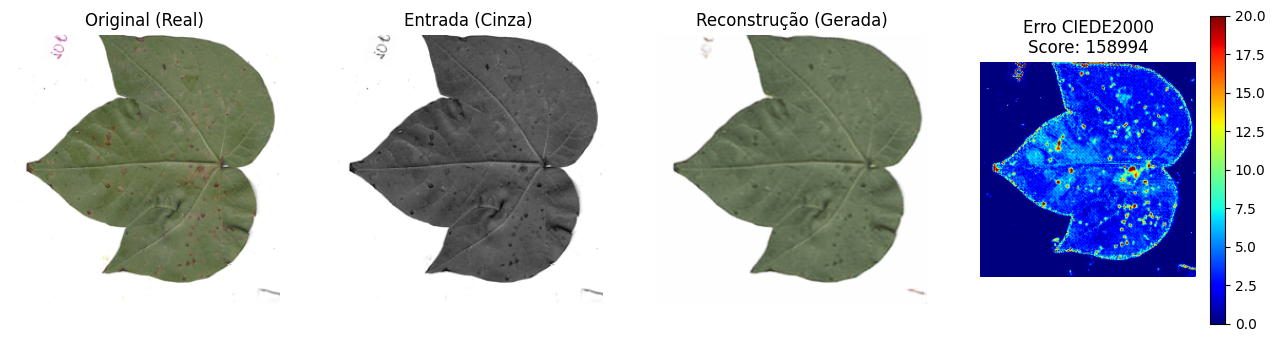

In [4]:
from skimage import color
import numpy as np

def detectar_doenca(gerador, loader_teste, indice_imagem=0):

    gerador.eval()
    
    # pega imagem especifica
    dataset = loader_teste.dataset
    amostra = dataset[indice_imagem]
    
    real_A = amostra["cinza"].unsqueeze(0).to(device)
    real_B = amostra["colorida"].unsqueeze(0)        
    
    with torch.no_grad():
        fake_B = gerador(real_A).cpu() #cria versao î
    
    # prepara p CIEDE2000
    # sai [-1, 1] e qeremos [0, 1] e formato (H, W, 3)
    img_real = real_B[0].permute(1, 2, 0).numpy() * 0.5 + 0.5
    img_fake = fake_B[0].permute(1, 2, 0).numpy() * 0.5 + 0.5
    
    # Converter RGB para Lab
    real_lab = color.rgb2lab(img_real)
    fake_lab = color.rgb2lab(img_fake)
    
    diferenca = color.deltaE_ciede2000(real_lab, fake_lab)
    
    score_anomalia = np.sum(diferenca)
    
    return img_real, img_fake, diferenca, score_anomalia

################
# carregar dados de teste
dataset_teste = DatasetFolhas(raiz=HIPERPARAMETROS["caminho_dados"], modo="teste")
loader_teste = DataLoader(dataset_teste, batch_size=1, shuffle=False)

# Pega a imagem número 0 (ou troque o número para ver outras)
img_real, img_fake, mapa_calor, score = detectar_doenca(gerador, loader_teste, indice_imagem=1)

# plotar
fig, ax = plt.subplots(1, 4, figsize=(16, 4))
ax[0].imshow(img_real)
ax[0].set_title("Original (Real)")
ax[0].axis("off")

ax[1].imshow(color.rgb2gray(img_real), cmap='gray')
ax[1].set_title("Entrada (Cinza)")
ax[1].axis("off")

ax[2].imshow(img_fake)
ax[2].set_title("Reconstrução (Gerada)")
ax[2].axis("off")

# heat map, cor quente = doença
im = ax[3].imshow(mapa_calor, cmap='jet', vmin=0, vmax=20) # contraste
ax[3].set_title(f"Erro CIEDE2000\nScore: {score:.0f}")
ax[3].axis("off")
plt.colorbar(im, ax=ax[3])
plt.show()

## Finalmente, vamos varrer o dataset e guardar os scores

Iniciando avaliação completa do Teste...
Processado 0/150...
Processado 20/150...
Processado 40/150...
Processado 60/150...
Processado 80/150...
Processado 100/150...
Processado 120/150...
Processado 140/150...
Avaliação concluída!


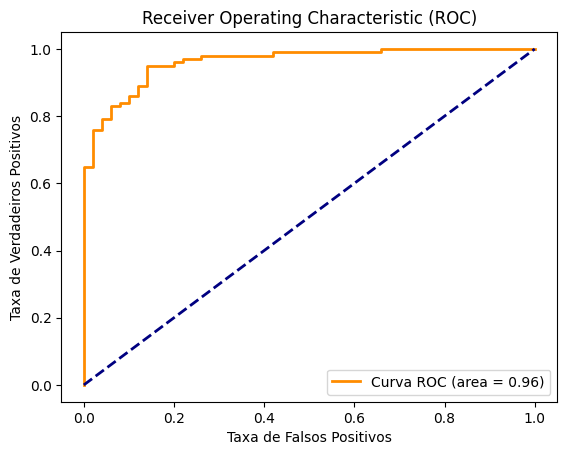


--- RESULTADOS FINAIS ---
Threshold ideal (Corte): 102778.81
AUC: 0.9618
Precisão: 0.9307
Recall: 0.9400
F1-Score: 0.9353


In [5]:
from sklearn.metrics import roc_curve, auc, precision_recall_fscore_support

scores = []
labels_reais = [] # 0 = Saudável, 1 = Doente

print("Iniciando avaliação completa do Teste...")

for i in range(len(dataset_teste)):
    
    caminho = dataset_teste.arquivos[i]
    if "saudavel" in caminho:
        label = 0 # Normal
    else:
        label = 1 # Doente 
        
    _, _, _, score = detectar_doenca(gerador, loader_teste, indice_imagem=i)
    
    scores.append(score)
    labels_reais.append(label)
    
    if i % 20 == 0:
        print(f"Processado {i}/{len(dataset_teste)}...")

print("Avaliação concluída!")

#curvas
fpr, tpr, thresholds = roc_curve(labels_reais, scores)
roc_auc = auc(fpr, tpr)

plt.figure()
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'Curva ROC (area = {roc_auc:.2f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlabel('Taxa de Falsos Positivos')
plt.ylabel('Taxa de Verdadeiros Positivos')
plt.title('Receiver Operating Characteristic (ROC)')
plt.legend(loc="lower right")
plt.show()

#metricas
# vamos usar critério Youden (pto mais alto da curva)
melhor_idx = np.argmax(tpr - fpr)
melhor_threshold = thresholds[melhor_idx]

# discreto
predicoes = [1 if s > melhor_threshold else 0 for s in scores]

precision, recall, f1, _ = precision_recall_fscore_support(labels_reais, predicoes, average='binary')

print(f"\n--- RESULTADOS FINAIS ---")
print(f"Threshold ideal (Corte): {melhor_threshold:.2f}")
print(f"AUC: {roc_auc:.4f}")
print(f"Precisão: {precision:.4f}")
print(f"Recall: {recall:.4f}")
print(f"F1-Score: {f1:.4f}")

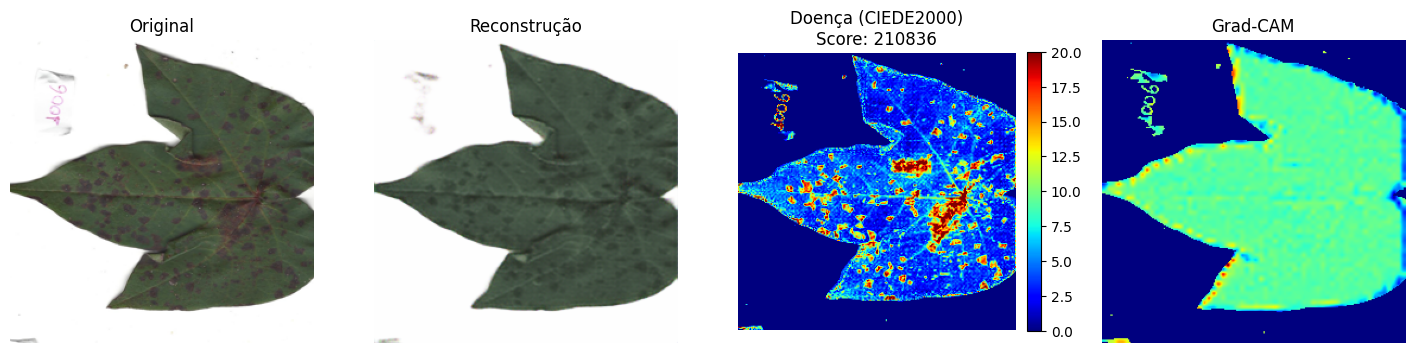

Modelo salvo!


In [6]:
import torch.nn.functional as F
import cv2
import numpy as np
import matplotlib.pyplot as plt

class GradCAM:
    def __init__(self, model, target_layer):
        self.model = model
        self.target_layer = target_layer
        self.gradients = None
        self.activations = None
        self.handles = []
        self.handles.append(self.target_layer.register_forward_hook(self.save_activation))
        self.handles.append(self.target_layer.register_full_backward_hook(self.save_gradient))

    def save_activation(self, module, input, output):
        self.activations = output

    def save_gradient(self, module, grad_input, grad_output):
        self.gradients = grad_output[0]

    def remove_hooks(self):
        for handle in self.handles: handle.remove()

    def __call__(self, img_cinza, img_colorida):
        self.model.zero_grad()
        output = self.model(img_cinza, img_colorida)
        score = output.mean()
        score.backward()
        
        weights = torch.mean(self.gradients, dim=[2, 3], keepdim=True)
        heatmap = torch.sum(weights * self.activations, dim=1, keepdim=True)
        heatmap = F.relu(heatmap)
        heatmap = heatmap.detach().cpu().numpy().squeeze()
        
        if np.max(heatmap) - np.min(heatmap) == 0:
            heatmap = np.zeros_like(heatmap)
        else:
            heatmap = (heatmap - np.min(heatmap)) / (np.max(heatmap) - np.min(heatmap))
        
        heatmap = cv2.resize(heatmap, (256, 256))
        return heatmap

def visualizacao_completa(gerador, discriminador, dataset, indice=0):
    gerador.eval()
    discriminador.eval()
    
    amostra = dataset[indice]
    real_A = amostra["cinza"].unsqueeze(0).to(device)    
    real_B = amostra["colorida"].unsqueeze(0).to(device)

    with torch.no_grad():
        fake_B = gerador(real_A)

    # gradcam
    camada_alvo = discriminador.modelo[2] 
    grad_cam = GradCAM(discriminador, camada_alvo)
    
    with torch.set_grad_enabled(True):
        mapa_atencao = grad_cam(fake_B.detach(), real_A)
    
    grad_cam.remove_hooks()

    img_real = np.clip(real_B.squeeze().cpu().permute(1, 2, 0).numpy() * 0.5 + 0.5, 0, 1)
    img_fake = np.clip(fake_B.squeeze().cpu().permute(1, 2, 0).numpy() * 0.5 + 0.5, 0, 1)
    input_cinza = real_A.squeeze().cpu().numpy() 

    # mask fundo branco
    mascara = input_cinza < 0.9

    real_lab = color.rgb2lab(img_real)
    fake_lab = color.rgb2lab(img_fake)
    diferenca = color.deltaE_ciede2000(real_lab, fake_lab)
    
    # limpa fundo (ciede e gradcam)
    diferenca[~mascara] = 0 
    mapa_atencao[~mascara] = 0

    fig, ax = plt.subplots(1, 4, figsize=(18, 5))
    
    ax[0].imshow(img_real)
    ax[0].set_title("Original")
    ax[0].axis('off')
    
    ax[1].imshow(img_fake)
    ax[1].set_title("Reconstrução")
    ax[1].axis('off')
    
    im = ax[2].imshow(diferenca, cmap='jet', vmin=0, vmax=20) 
    ax[2].set_title(f"Doença (CIEDE2000)\nScore: {np.sum(diferenca):.0f}")
    ax[2].axis('off')
    plt.colorbar(im, ax=ax[2], fraction=0.046, pad=0.04)
    
    ax[3].imshow(mapa_atencao, cmap='jet')
    ax[3].set_title("Grad-CAM")
    ax[3].axis('off')

    plt.show()

# rodar
ds_teste = DatasetFolhas("./data/", modo="teste")
visualizacao_completa(gerador, discriminador, ds_teste, indice=11)

torch.save(gerador.state_dict(), "gerador_final.pth")
print("Modelo salvo!")